# ABS/MBS Waterfall Engine & Tranche Loss Distribution

In 2007–08 senior mortgage tranches rated AAA lost money because their risk depended on how loan losses moved together, not just on how large they were on average. A securitisation slices a pool's losses into tranches, and only the full loss distribution says how risky each slice is. This notebook builds the cash-flow waterfall of a mortgage deal and simulates that distribution.

**What it does.** It builds a monthly cash-flow waterfall for a residential mortgage securitisation (senior, mezzanine and junior notes, overcollateralisation and excess spread). The waterfall is driven by default, liquidation, prepayment and severity inputs estimated on ten loan vintages, four of them through the 2008 crisis, and 10,000 economic scenarios are simulated with a systematic credit factor whose volatility is set by how much the vintages differed.

It produces each tranche's loss distribution, probability of loss, expected loss, weighted-average life and yield, shows how credit enhancement and the OC turbo protect the senior notes, measures how tranche risk responds to default correlation, and places the realised losses of the 2005–08 vintages in the simulated distribution.

**Data.** Fannie Mae Single-Family Loan Performance data (2005–2008 acquisitions) and the Freddie Mac Single-Family Loan-Level Dataset (vintages 2018–2023): default and prepayment curves by loan age, liquidation rates, realised severities and vintage losses; the 30-year mortgage rate (FRED). The deal structure, coupons and the median-scenario severity are stated assumptions.

**Methods.** Through-the-cycle hazard curves averaged over vintages, a factor volatility estimated from the dispersion of vintage default rates, a one-factor frailty model for defaults (lognormal hazard multiplier) with correlated severity and prepayment, and a vectorised monthly waterfall (interest, sequential principal, reverse-sequential loss allocation, OC target and turbo).

Tranche metrics come from Monte Carlo, compared with a large-homogeneous-pool (Vasicek) model, with sensitivity to the systematic volatility.

**Key output.** The calibration from ten vintages, the pool loss distribution against the tranche attachment points and against realised crisis losses, each tranche's PD, EL, 99th-percentile loss, WAL and yield, cash-flow paths for a typical and a stressed scenario, and the correlation sensitivity.

## 1. Why tranche risk is not pool risk

A securitisation re-packages a pool's losses into slices. Each tranche absorbs pool losses between an **attachment** point $A$ and a **detachment** point $D$:

$$L_\text{tranche}=\frac{\min(\max(L_\text{pool}-A,0),\,D-A)}{D-A}.$$

So tranche risk depends on the whole **distribution** of pool losses, not on its mean. The tail is set by how much defaults move together: with independent loans the pool loss is almost deterministic and a senior tranche is riskless; with a common factor (house prices, unemployment) the pool loss distribution is wide and skewed, and senior tranches carry tail risk. That was the lesson of 2007–08.

**Structural protection** beyond subordination:
- **Excess spread:** pool interest minus note coupons and fees, the first line of loss absorption every month.
- **Overcollateralisation (OC):** pool balance in excess of note balance. When OC falls below its target, excess spread is diverted to pay down the senior notes (**turbo**) until it is rebuilt.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 31
N_SIMS = 10_000
POOL = 500e6  # $ pool balance at closing
WAC, SERVICING = 0.065, 0.0025  # pool coupon and servicing fee (annual)
TERM = 360
TRANCHES = {  # name: (size as share of the pool, coupon)
    "Class A (senior)": (0.85, 0.0525),
    "Class M (mezzanine)": (0.07, 0.0650),
    "Class B (junior)": (0.04, 0.0850),
}
# equity / OC at closing and its target (share of the original pool)
OC_INITIAL, OC_TARGET = 0.04, 0.04
# loss severity in the median scenario (through-the-cycle assumption); the
# volatility of the systematic factor and the severity slope are estimated
# from the 2005-08 and 2018-23 vintages in section 3
SEV_MEAN = 0.30
# prepayment falls in bad states (log multiplier per s.d.)
PP_BETA = -0.25

print(f"duckdb {duckdb.__version__} · run on {dt.date.today():%Y-%m-%d}")

duckdb 1.5.6 · run on 2026-10-28


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Freddie Mac Single-Family Loan-Level Dataset (sample files)
# Download manually (free registration, non-commercial licence):
# https://freddiemac.embs.com/FLoan/Data/download.php
# → "Sample Dataset" → sample_YYYY.zip, saved in data/freddie_mac/ at the repo
# root.
# The files are licensed and are never committed: data/ is in .gitignore.
import zipfile


def find_shared_data(name):
    """
    Find data/<name> in this project's folder or any folder above it, up to the
    repo root (works with sub-folders).
    """
    for d in [PROJECT_DIR, *PROJECT_DIR.parents]:
        if (d / "data" / name).exists():
            return d / "data" / name
        if (d / ".git").exists():
            break
    return None


FREDDIE_DIR = find_shared_data("freddie_mac")
if FREDDIE_DIR is None or not list(FREDDIE_DIR.glob("sample_*.zip")):
    raise FileNotFoundError(
        "Put the Freddie Mac sample_YYYY.zip files in FIN/data/freddie_mac/"
        " (see the link above)."
    )
FM_TXT = DATA_DIR / "freddie_txt"
FM_TXT.mkdir(exist_ok=True)
for z in sorted(FREDDIE_DIR.glob("sample_*.zip")):
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))

ORIG_COLS = [
    "credit_score",
    "first_pay_date",
    "first_time_buyer",
    "maturity_date",
    "msa",
    "mi_pct",
    "n_units",
    "occupancy",
    "cltv",
    "dti",
    "orig_upb",
    "ltv",
    "orig_rate",
    "channel",
    "ppm_flag",
    "amort_type",
    "state",
    "prop_type",
    "zip3",
    "loan_id",
    "purpose",
    "orig_term",
    "n_borrowers",
    "seller_servicer",
    "super_conforming",
    "pre_relief_id",
    "program",
    "relief_refi",
    "valuation_method",
    "io_flag",
    "mi_cancel",
]
PERF_COLS = {
    0: "loan_id",
    1: "period",
    2: "upb",
    3: "dq",
    4: "age",
    5: "months_left",
    7: "mod_flag",
    8: "zb_code",
    9: "zb_date",
    10: "rate",
    21: "actual_loss",
    25: "eltv",
    26: "zb_upb",
    29: "assistance",
}


def freddie_con():
    con = duckdb.connect(
        str(DATA_DIR / "freddie.duckdb")
    )  # tables on disk, not in the notebook's memory
    con.execute("SET enable_progress_bar = false")
    con.execute("SET memory_limit = '2GB'")
    orig_sel = ", ".join(
        f"column{i:02d} AS {c}" for i, c in enumerate(ORIG_COLS)
    )
    con.execute(
        f"""CREATE OR REPLACE VIEW orig AS SELECT {orig_sel}
                    FROM read_csv('{(FM_TXT / "sample_orig_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    perf_sel = ", ".join(f"column{i:02d} AS {c}" for i, c in PERF_COLS.items())
    con.execute(
        f"""CREATE OR REPLACE VIEW perf AS SELECT {perf_sel}
                    FROM read_csv('{(FM_TXT / "sample_perf_*.txt").as_posix()}', delim='|', header=false, all_varchar=true)"""
    )
    return con


# --- Fannie Mae Single-Family Loan Performance data, 2005-2008 acquisitions
# Download manually (free registration): https://capitalmarkets.fanniemae.com
# → Single-Family Loan Performance Data → quarterly files 2005Q1 ... 2008Q4,
# saved as data/fannie_mae/2005Q1.zip ... at the repo root. The first run
# builds a sample in the Freddie Mac sample format (12,500 loans per quarter,
# 50,000 per vintage, monthly history) in data/fannie_mae/sample/ and reuses
# it afterwards. The files are licensed and are never committed.
import random


def _ym(s):
    return s[2:] + s[:2] if len(s) == 6 else ""


def _num(s, d=0.0):
    try:
        return float(s)
    except ValueError:
        return d


def fannie_quarter_to_sample(zip_path, yy, q, out_dir, keep=12_500,
                             share=0.08):
    """Filter one quarterly file (loan id mod 1000 < 80), draw `keep` loans
    and append them to sample_orig_20yy.txt / sample_perf_20yy.txt."""
    with zipfile.ZipFile(zip_path) as zf:
        name = zf.namelist()[0]
        lines = []
        with zf.open(name) as f:
            for raw in f:
                line = raw.decode("latin-1")
                lid = line.split("|", 3)[1]
                if int(lid) % 1000 < share * 1000:
                    lines.append(line)
    ids, seen = [], set()
    for line in lines:
        i = line.split("|", 3)[1]
        if i not in seen:
            seen.add(i)
            ids.append(i)
    random.seed(int(f"20{yy}{q}"))
    chosen = set(random.sample(ids, min(keep, len(ids))))
    new_id = {i: f"F{yy}Q{q}{k:07d}" for k, i in enumerate(sorted(chosen))}
    fo = open(out_dir / f"sample_orig_20{yy}.txt", "a")
    fp = open(out_dir / f"sample_perf_20{yy}.txt", "a")
    done, last_age = set(), {}
    for line in lines:
        x = line.rstrip("\n").split("|")
        lid = x[1]
        if lid not in chosen:
            continue
        p = lambda k: x[k - 1] if k - 1 < len(x) else ""
        nid = new_id[lid]
        if lid not in done:
            done.add(lid)
            purpose = {"P": "P", "C": "C", "R": "N"}.get(p(27), "9")
            o = [p(24) or "9999", _ym(p(15)),
                 p(26) if p(26) in ("Y", "N") else "9", _ym(p(19)), p(32),
                 p(34) or "0", p(29), p(30), p(21) or "999", p(23) or "999",
                 str(int(_num(p(10)))), p(20) or "999", p(8), p(4) or "9",
                 p(36) or "N", p(35) or "FRM", p(31), p(28), p(33), nid,
                 purpose, p(13), p(22) or "99", (p(5) or "OTHER").upper(),
                 p(87) or "N", "", p(79), p(103) or "N", p(86) or "9",
                 p(37) or "N", p(43) or "9999"]
            fo.write("|".join(o) + "\n")
        per, zb, upb = _ym(p(3)), p(44), _num(p(12))
        age = int(_num(p(16), -1))
        if age < 0:
            age = last_age.get(lid, -1) + 1
        last_age[lid] = age
        if upb == 0 and not zb:         # masked in the first months
            upb = _num(p(11)) or _num(p(10))
        loss = ""
        if p(59) or p(60) or p(62):     # disposition: Freddie-style loss
            zbu, rate = _num(p(46)), _num(p(9)) or _num(p(8))
            lp, zd = _ym(p(51)), _ym(p(45)) or per
            gap = ((int(zd[:4]) - int(lp[:4])) * 12 + int(zd[4:])
                   - int(lp[4:])) if lp and zd else 0
            dai = zbu * rate / 1200 * max(gap - 1, 0)
            costs = sum(_num(p(k)) for k in (54, 55, 56, 57, 58))
            proceeds = sum(_num(p(k)) for k in (59, 60, 61, 62))
            loss = f"{proceeds - zbu - costs - dai:.2f}"
        r = [""] * 35
        r[0], r[1], r[2] = nid, per, f"{0.0 if zb else upb:.2f}"
        r[3] = "" if p(40) == "XX" else p(40)
        r[4], r[5] = str(age), p(18)
        r[7] = "Y" if p(42) == "Y" else ""
        r[8], r[9], r[10] = zb, _ym(p(45)), p(9) or p(8)
        r[11], r[12] = p(63) or "0.00", _ym(p(51))
        r[21], r[26], r[29] = loss, (p(46) if zb else ""), p(102)
        r[31] = f"{_num(p(110)) or (0.0 if zb else upb):.2f}"
        r[33] = (p(6) or "OTHER").upper()
        fp.write("|".join(r) + "\n")
    fo.close()
    fp.close()


def fannie_sample_zips():
    src = find_shared_data("fannie_mae")
    if src is None:
        return []
    out = src / "sample"
    if not list(out.glob("sample_*.zip")):
        quarters = sorted(src.glob("20??Q?.zip"))
        if not quarters:
            return []
        out.mkdir(exist_ok=True)
        tmp = DATA_DIR / "fannie_build"
        tmp.mkdir(exist_ok=True)
        for z in quarters:              # about 1-2 minutes per quarter
            print("sampling", z.name)
            fannie_quarter_to_sample(z, z.stem[2:4], z.stem[-1], tmp)
        for y in sorted({z.stem[:4] for z in quarters}):
            with zipfile.ZipFile(out / f"sample_{y}.zip", "w",
                                 zipfile.ZIP_DEFLATED) as zf:
                for kind in ["orig", "perf"]:
                    zf.write(tmp / f"sample_{kind}_{y}.txt",
                             f"sample_{kind}_{y}.txt")
    return sorted(out.glob("sample_*.zip"))


for z in fannie_sample_zips():
    with zipfile.ZipFile(z) as f:
        for m in f.namelist():
            if not (FM_TXT / m).exists():
                f.extract(m, FM_TXT)
VINTAGES = sorted(int(p.stem[-4:]) for p in FM_TXT.glob("sample_orig_*.txt"))


## 3. Calibration from ten vintages: four through the crisis, six since 2018

The loan data cover two very different periods: Fannie Mae's 2005–08 vintages, which defaulted in the 2008–2012 housing crisis, and Freddie Mac's 2018–23 vintages, which saw rising house prices and pandemic forbearance. Together they pin down the three inputs the waterfall needs.

- **Default curve:** the monthly default rate (90+ days delinquent outside forbearance, or a credit event) by loan age, computed **for each vintage separately** and then averaged with equal weight per vintage, a through-the-cycle curve. Beyond the oldest observed age it fades with $e^{-(a-a_\text{max})/72}$.
- **From default to liquidation:** many loans that reach 90 days delinquent cure or are modified. The crisis vintages show what share of them ended in a foreclosure, short or note sale, and the pool's loss-generating hazard is the default curve times that share.
- **Volatility of the systematic factor $\sigma$:** vintages differ mainly by when they met the economy. The standard deviation of the logarithm of the 60-month cumulative default rate across the vintages old enough to have one is the dispersion the lognormal default multiplier must reproduce.
- **Severity:** realised losses on the crisis disposals (balance, unpaid interest and costs, net of sale and insurance proceeds) set how bad severity gets in the worst vintages; the slope $\beta_\text{sev}$ is chosen so that the 1-in-100 scenario has the worst vintage's severity. The median-scenario severity stays at a through-the-cycle 30%.
- **Prepayment curve:** the age profile of payoffs with a refinancing incentive between −0.5 and +0.5 points (housing turnover and seasoning at par), from all ten vintages.

In [3]:
con = freddie_con()
mort = (
    fred.get_series("MORTGAGE30US", observation_start="2004-01-01")
    .resample("MS")
    .mean()
)
con.register(
    "mort",
    pd.DataFrame({
        "per": mort.index.year * 100 + mort.index.month,
        "mort_rate": mort.to_numpy(),
    }),
)
con.execute("""
CREATE OR REPLACE TABLE x AS
WITH p AS (SELECT loan_id, CAST(period AS INT) AS per, CAST(age AS INT) AS age, dq, zb_code, COALESCE(assistance, '') AS a,
                  2000 + CAST(substr(loan_id, 2, 2) AS INT) AS vintage FROM perf),
fd AS (SELECT loan_id, MIN(per) AS d_per FROM p WHERE (dq NOT IN ('00', '01', '02', 'RA') AND a <> 'F') OR zb_code IN ('02', '03', '09', '15') GROUP BY 1)
SELECT p.vintage, p.age, COALESCE(fd.d_per = p.per, FALSE)::INT AS d, COALESCE(p.zb_code = '01', FALSE)::INT AS pp,
       TRY_CAST(o.orig_rate AS DOUBLE) - m.mort_rate AS inc
FROM p JOIN orig o USING (loan_id) JOIN mort m USING (per) LEFT JOIN fd USING (loan_id)
WHERE fd.d_per IS NULL OR p.per <= fd.d_per""")
by_v = con.execute("""SELECT vintage, age, COUNT(*) AS n, AVG(d) AS mdr FROM x GROUP BY 1, 2 ORDER BY 1, 2""").df()
by_v = by_v[by_v["n"] >= 2_000]
par = con.execute("""SELECT age, AVG(pp) AS smm_par, COUNT(*) AS n FROM x WHERE inc BETWEEN -0.5 AND 0.5
                     GROUP BY 1 HAVING COUNT(*) >= 5000 ORDER BY 1""").df().set_index("age")
ages = np.arange(TERM)
vint_curves = by_v.pivot(index="age", columns="vintage", values="mdr")
mdr_ttc = vint_curves.mean(axis=1)               # equal weight per vintage
mdr = (mdr_ttc.rolling(7, center=True, min_periods=1).mean().reindex(ages)
       .ffill().fillna(mdr_ttc.iloc[0]).to_numpy().copy())
last_age = int(mdr_ttc.index.max())
mdr[last_age:] *= np.exp(-(ages[last_age:] - last_age) / 72)
smm = (par["smm_par"].rolling(7, center=True, min_periods=1).mean()
       .reindex(ages).ffill().bfill().to_numpy())
# not every 90+ day default ends in a liquidation: many cure or are modified.
# The waterfall loses money only on liquidations (credit events).
liq = con.execute("""
WITH p AS (SELECT loan_id, dq, zb_code, COALESCE(assistance, '') AS a FROM perf
           WHERE substr(loan_id, 2, 2) <= '08')
SELECT COUNT(DISTINCT CASE WHEN zb_code IN ('02', '03', '09', '15') THEN loan_id END) * 1.0
       / COUNT(DISTINCT CASE WHEN (dq NOT IN ('00', '01', '02', 'RA') AND a <> 'F')
                               OR zb_code IN ('02', '03', '09', '15') THEN loan_id END) AS share
FROM p""").fetchone()[0]
LIQ_SHARE = float(liq)
mdr_pool = np.clip(mdr * LIQ_SHARE, 0, 0.05)
# sigma from the dispersion of 60-month cumulative default across vintages
cum60 = vint_curves.loc[:59].dropna(axis=1).pipe(
    lambda c: 1 - np.prod(1 - c, axis=0))
SIGMA = float(np.log(cum60).std(ddof=1))
# severity: crisis disposals
sev = con.execute("""
SELECT 2000 + CAST(substr(loan_id, 2, 2) AS INT) AS vintage, -TRY_CAST(actual_loss AS DOUBLE) / NULLIF(TRY_CAST(zb_upb AS DOUBLE), 0) AS severity,
       TRY_CAST(zb_upb AS DOUBLE) AS upb
FROM perf WHERE zb_code IN ('02', '03', '09', '15') AND TRY_CAST(actual_loss AS DOUBLE) IS NOT NULL""").df()
sev = sev[sev["severity"].between(-0.5, 1.5)]
SEV_BY_VINTAGE = sev.groupby("vintage").apply(
    lambda g: pd.Series({"disposals": len(g),
                         "severity (balance-weighted)": np.average(
                             g["severity"], weights=g["upb"])}),
    include_groups=False)
worst_sev = SEV_BY_VINTAGE.loc[SEV_BY_VINTAGE["disposals"] >= 500,
                               "severity (balance-weighted)"].max()
SEV_BETA = (worst_sev - SEV_MEAN) / stats.norm.ppf(0.99)
# realised cumulative loss of each crisis vintage, as a share of its pool
real_loss = con.execute("""
SELECT 2000 + CAST(substr(o.loan_id, 2, 2) AS INT) AS vintage,
       -SUM(COALESCE(TRY_CAST(p.actual_loss AS DOUBLE), 0)) / ANY_VALUE(t.upb0) AS realised_loss
FROM orig o JOIN perf p USING (loan_id)
JOIN (SELECT 2000 + CAST(substr(loan_id, 2, 2) AS INT) AS vintage, SUM(TRY_CAST(orig_upb AS DOUBLE)) AS upb0
      FROM orig GROUP BY 1) t ON t.vintage = 2000 + CAST(substr(o.loan_id, 2, 2) AS INT)
GROUP BY 1 ORDER BY 1""").df().set_index("vintage")
S = np.cumprod(1 - mdr_pool - smm)
life_def = np.sum(np.concatenate([[1], S[:-1]]) * mdr_pool)
VINTAGE_TAB = pd.DataFrame({"60-month cumulative default": cum60,
                            "realised loss to date": real_loss["realised_loss"]})
print(
    f"Through-the-cycle seasoned MDR {mdr[36:60].mean() * 1e4:.2f} bp/month"
    f" (CDR {(1 - (1 - mdr[36:60].mean()) ** 12) * 100:.2f}%) · par CPR"
    f" {(1 - (1 - smm[36:60].mean()) ** 12) * 100:.1f}% · lifetime default"
    f" {life_def:.2%} (liquidations: {LIQ_SHARE:.0%} of 90+ defaults) · σ ="
    f" {SIGMA:.2f} from {cum60.size} vintages ·"
    f" worst vintage severity {worst_sev:.1%} → β_sev = {SEV_BETA:.3f}"
)
display(SEV_BY_VINTAGE.style.format({"disposals": "{:,.0f}",
                                     "severity (balance-weighted)": "{:.1%}"}))
VINTAGE_TAB.style.format("{:.2%}")

Through-the-cycle seasoned MDR 21.09 bp/month (CDR 2.50%) · par CPR 12.1% · lifetime default 6.72% (liquidations: 51% of 90+ defaults) · σ = 0.95 from 8 vintages · worst vintage severity 45.3% → β_sev = 0.066


,disposals,severity (balance-weighted)
vintage,,
2005,"2,768",41.1%
2006,"3,853",45.3%
2007,"4,362",42.9%
2008,"2,572",33.0%
2018,61,-9.0%
2019,42,-11.1%
2020,19,-11.7%
2021,21,-8.1%
2022,41,-8.7%


,60-month cumulative default,realised loss to date
vintage,,
2005,8.34%,2.15%
2006,16.01%,3.48%
2007,20.80%,3.67%
2008,15.91%,1.56%
2018,5.99%,-0.01%
2019,4.84%,-0.01%
2020,1.71%,-0.00%
2021,2.01%,-0.00%
2022,nan%,-0.01%


## 4. Scenarios and the waterfall

Each scenario draws one systematic factor $Z\sim N(0,1)$ (bad states are high $Z$) and applies it for the life of the deal:

- default hazard × $\exp(\sigma Z-\sigma^2/2)$, so the expected multiplier is 1;
- severity $=\text{clip}(\text{SEV}_\text{mean}+\beta_\text{sev}Z,\,5\%,\,80\%)$;
- prepayment × $\exp(\beta_\text{pp}Z)$: refinancing dries up in a downturn.

Monthly waterfall, vectorised across scenarios:
1. Collections: scheduled principal, prepayments, recoveries on defaults, and interest on the performing balance.
2. Fees, then note interest **sequentially** (A, M, B). Unpaid interest is carried forward.
3. Principal collections (scheduled + prepaid + recovered) pay the notes **sequentially**.
4. Excess spread first covers the month's losses; if OC is below target it **turbos** the most senior outstanding note; anything left goes to the residual holder.
5. Losses not covered by excess spread reduce OC first, then write down B, then M, then A.

In [4]:
rng = np.random.default_rng(SEED)
Z = rng.standard_normal(N_SIMS)


def run_deal(Z, sigma=SIGMA, keep_paths=None):
    n = len(Z)
    mult = np.exp(sigma * Z - sigma**2 / 2)
    sev = np.clip(SEV_MEAN + SEV_BETA * Z, 0.05, 0.80)
    ppm = np.exp(PP_BETA * Z)
    names = list(TRANCHES)
    bal = {k: np.full(n, TRANCHES[k][0] * POOL) for k in names}
    cpn = {k: TRANCHES[k][1] / 12 for k in names}
    shortfall = {k: np.zeros(n) for k in names}
    # monthly cash to each note (for yields and WAL)
    cf = {k: [] for k in names}
    princ_paid = {k: np.zeros(n) for k in names}
    wal_num = {k: np.zeros(n) for k in names}
    writedown = {k: np.zeros(n) for k in names}
    pool = np.full(n, POOL)
    r = WAC / 12
    residual = np.zeros(n)
    cum_loss = np.zeros(n)
    path_log = []
    for t in range(TERM):
        rem = TERM - t
        h_d = np.minimum(mdr_pool[t] * mult, 0.2)
        h_p = np.minimum(smm[t] * ppm, 0.5)
        defaults = pool * h_d
        loss = defaults * sev
        recov = defaults - loss
        perf = pool - defaults
        sched = perf * (r / ((1 + r) ** rem - 1)) if rem > 1 else perf
        prepaid = (perf - sched) * h_p
        interest = perf * r
        avail_int = interest - pool * SERVICING / 12
        # 2. note interest, sequential
        for k in names:
            due = bal[k] * cpn[k] + shortfall[k]
            paid = np.minimum(avail_int, due)
            shortfall[k] = due - paid
            avail_int -= paid
            cf[k].append(paid.copy())
        # 3. sequential principal
        principal = sched + prepaid + recov
        pool = perf - sched - prepaid
        excess = avail_int
        cover = np.minimum(
            excess, loss
        )  # 4a. excess spread covers this month's losses
        excess -= cover
        principal += cover
        uncovered = loss - cover
        cum_loss += loss
        notes = sum(bal[k] for k in names)
        oc = pool - (notes - principal)
        # 4b. OC turbo
        turbo = np.clip(np.minimum(excess, OC_TARGET * POOL - oc), 0, None)
        excess -= turbo
        principal += turbo
        # 4c. residual
        residual += excess
        for k in names:
            pay = np.minimum(principal, bal[k])
            bal[k] -= pay
            principal -= pay
            cf[k][-1] += pay
            princ_paid[k] += pay
            wal_num[k] += pay * (t + 1) / 12
        # surplus principal once all notes are retired
        residual += principal
        notes = sum(bal[k] for k in names)
        # 5. losses beyond OC write notes down, junior first
        deficit = np.clip(notes - pool, 0, None)
        for k in reversed(names):
            wd = np.minimum(deficit, bal[k])
            bal[k] -= wd
            writedown[k] += wd
            deficit -= wd
        if keep_paths is not None:
            path_log.append({
                "month": t + 1,
                **{k: bal[k][keep_paths].copy() for k in names},
                "pool": pool[keep_paths].copy(),
                "excess": excess[keep_paths].copy(),
            })
        if (pool < 1).all():
            break
    out = {}
    for k in names:
        size = TRANCHES[k][0] * POOL
        # months x scenarios
        flows = np.vstack(cf[k])
        m = np.arange(1, flows.shape[0] + 1)

        def irr(col, m=m, size=size):  # bind this tranche's size and months
            f = lambda y: np.sum(col / (1 + y / 12) ** m) - size
            if col.sum() < 1e-6 * size:
                return -1.0
            try:
                return optimize_brentq(f, -0.99, 1.0)
            except ValueError:
                return np.nan

        out[k] = {
            "loss": writedown[k] / size,
            "int_short": shortfall[k] / size,
            "wal": wal_num[k] / np.maximum(princ_paid[k], 1),
            "flows": flows,
            "irr": irr,
        }
    return out, cum_loss / POOL, residual, path_log


from scipy.optimize import brentq as optimize_brentq

t0 = time.time()
res, pool_loss, residual, _ = run_deal(Z)
VINTAGE_TAB["percentile in simulated pool loss"] = [
    (pool_loss <= v).mean() if np.isfinite(v) else np.nan
    for v in VINTAGE_TAB["realised loss to date"]]
print(
    f"{N_SIMS:,} scenarios in {time.time() - t0:.0f}s · pool cumulative loss:"
    f" mean {pool_loss.mean():.2%}, median {np.median(pool_loss):.2%}, 99th"
    f" pct {np.percentile(pool_loss, 99):.2%}, 99.9th"
    f" {np.percentile(pool_loss, 99.9):.2%}"
)
VINTAGE_TAB.style.format("{:.2%}")

10,000 scenarios in 0s · pool cumulative loss: mean 2.37%, median 1.22%, 99th pct 16.81%, 99.9th 27.48%


,60-month cumulative default,realised loss to date,percentile in simulated pool loss
vintage,,,
2005,8.34%,2.15%,67.11%
2006,16.01%,3.48%,80.18%
2007,20.80%,3.67%,81.40%
2008,15.91%,1.56%,57.69%
2018,5.99%,-0.01%,0.00%
2019,4.84%,-0.01%,0.00%
2020,1.71%,-0.00%,0.00%
2021,2.01%,-0.00%,0.00%
2022,nan%,-0.01%,0.00%


## 5. Tranche metrics

In [5]:
att, rows = OC_INITIAL, []
for k in reversed(list(TRANCHES)):
    size = TRANCHES[k][0]
    L = res[k]["loss"]
    q = np.quantile(Z, [0.5, 0.99])
    yields = [
        res[k]["irr"](res[k]["flows"][:, int(np.argmin(np.abs(Z - z)))])
        for z in q
    ]
    rows.append({
        "tranche": k,
        "attachment %": att * 100,
        "detachment %": (att + size) * 100,
        "coupon %": TRANCHES[k][1] * 100,
        "P(loss > 0) %": (L > 1e-6).mean() * 100,
        "expected loss %": L.mean() * 100,
        "99th pct loss %": np.percentile(L, 99) * 100,
        "WAL (years, median)": np.median(res[k]["wal"]),
        "yield, median scenario %": yields[0] * 100,
        "yield, 1-in-100 scenario %": yields[1] * 100,
    })
    att += size
tranche_tab = pd.DataFrame(rows).set_index("tranche").iloc[::-1]

# Large-homogeneous-pool check: the same attachment points on the simulated
# pool-loss distribution, ignoring the waterfall
lhp = {}
a = OC_INITIAL
for k in reversed(list(TRANCHES)):
    d = a + TRANCHES[k][0]
    lhp[k] = (np.clip(pool_loss - a, 0, d - a) / (d - a)).mean() * 100
    a = d
tranche_tab["EL without excess spread %"] = pd.Series(lhp)
print(
    "Residual (excess spread + OC release) to the equity holder: mean"
    f" ${residual.mean() / 1e6:,.1f}mm on ${OC_INITIAL * POOL / 1e6:,.0f}mm"
    " of OC"
)
tranche_tab.round(3)

Residual (excess spread + OC release) to the equity holder: mean $48.2mm on $20mm of OC


,attachment %,detachment %,coupon %,P(loss > 0) %,expected loss %,99th pct loss %,"WAL (years, median)","yield, median scenario %","yield, 1-in-100 scenario %",EL without excess spread %
tranche,,,,,,,,,,
Class A (senior),15.00,100.00,5.25,0.45,0.04,0.00,4.95,5.25,5.25,0.09
Class M (mezzanine),8.00,15.00,6.50,2.22,1.16,55.45,14.36,6.50,3.24,2.98
Class B (junior),4.00,8.00,8.50,5.25,3.62,100.00,17.88,8.50,-29.63,10.19


### Correlation sensitivity

The same deal is re-run with the systematic volatility $\sigma$ from 0.25 (defaults nearly independent) to 1.40 (a 2008-style common factor). Expected pool loss stays the same by construction; only the dispersion changes.

In [6]:
sens = []
for sg in sorted({0.25, 0.50, round(SIGMA, 2), 1.00, 1.40}):
    r_, pl, _, _ = run_deal(Z, sigma=sg)
    row = {
        "σ": sg,
        "pool loss mean %": pl.mean() * 100,
        "pool loss 99th %": np.percentile(pl, 99) * 100,
    }
    for k in TRANCHES:
        row[f"{k.split()[1]} EL %"] = r_[k]["loss"].mean() * 100
        row[f"{k.split()[1]} P(loss) %"] = (r_[k]["loss"] > 1e-6).mean() * 100
    sens.append(row)
sens = pd.DataFrame(sens).set_index("σ")
sens.round(3)

,pool loss mean %,pool loss 99th %,A EL %,A P(loss) %,M EL %,M P(loss) %,B EL %,B P(loss) %
σ,,,,,,,,
0.25,2.07,6.29,0.00,0.00,0.01,0.01,0.02,0.05
0.50,2.22,9.63,0.00,0.02,0.06,0.20,0.66,1.37
0.95,2.37,16.87,0.04,0.47,1.17,2.27,3.65,5.25
1.00,2.38,17.67,0.04,0.56,1.35,2.51,3.93,5.55
1.40,2.32,23.35,0.14,1.51,2.43,3.78,5.32,6.83


## 6. Charts

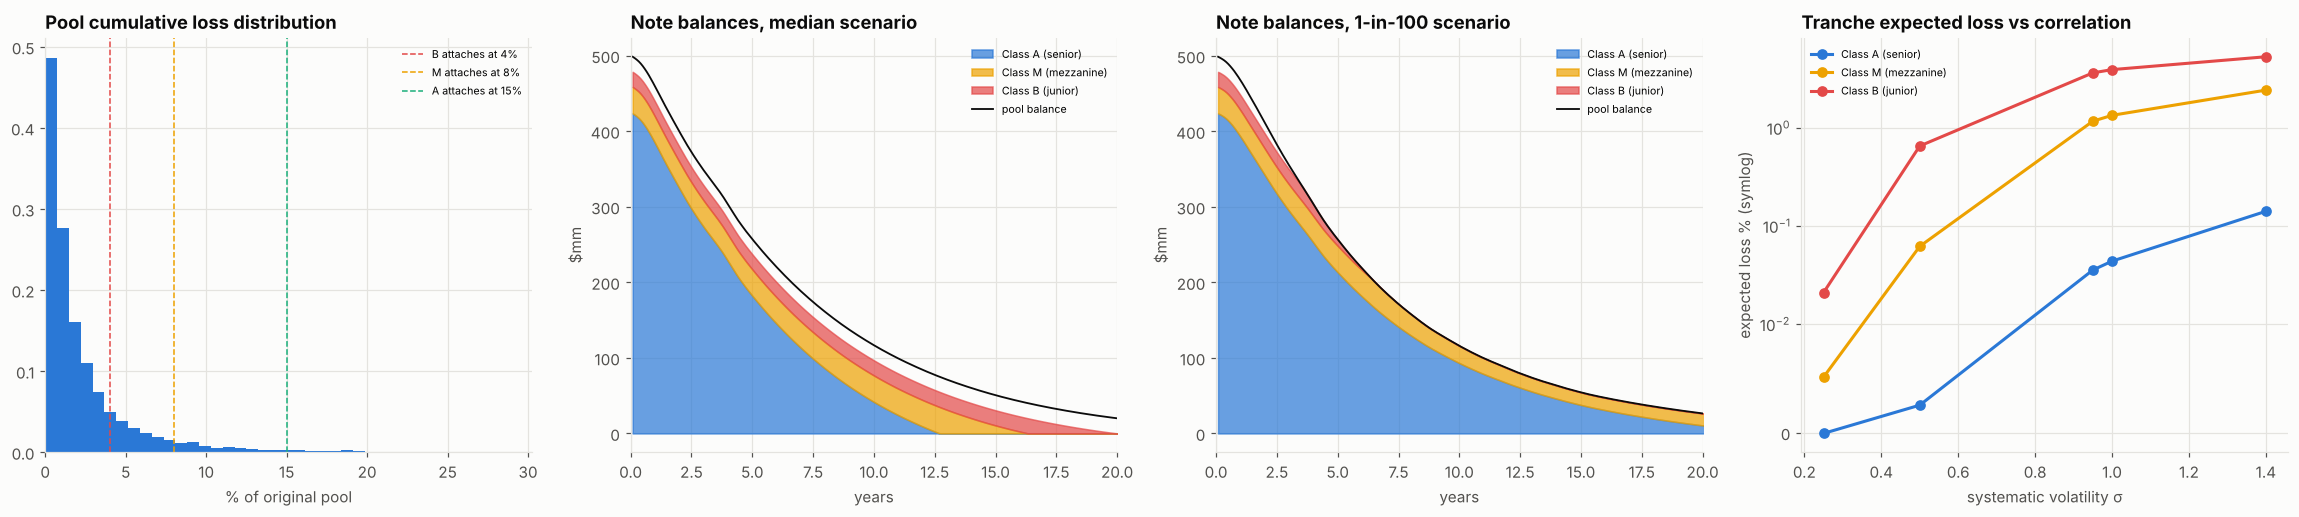

In [7]:
z_med, z_bad = np.median(Z), np.quantile(Z, 0.99)
idx = [int(np.argmin(np.abs(Z - z_med))), int(np.argmin(np.abs(Z - z_bad)))]
_, _, _, paths = run_deal(Z[idx], keep_paths=np.arange(2))
pl_df = pd.DataFrame(paths)
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
ax = axes[0]
ax.hist(pool_loss * 100, bins=80, color=PALETTE[0], density=True)
a = OC_INITIAL
for k, col in zip(
    reversed(list(TRANCHES)), [PALETTE[7], PALETTE[3], PALETTE[2]]
):
    ax.axvline(
        a * 100,
        color=col,
        ls="--",
        lw=1,
        label=f"{k.split()[1]} attaches at {a * 100:.0f}%",
    )
    a += TRANCHES[k][0]
ax.set_xlim(0, np.percentile(pool_loss, 99.9) * 100 * 1.1)
ax.set_title("Pool cumulative loss distribution")
ax.set_xlabel("% of original pool")
ax.legend(fontsize=7)
for ax, j, lab in [
    (axes[1], 0, "median scenario"),
    (axes[2], 1, "1-in-100 scenario"),
]:
    m_ = pl_df["month"] / 12
    bottom = np.zeros(len(pl_df))
    for k, col in zip(TRANCHES, [PALETTE[0], PALETTE[3], PALETTE[7]]):
        v = np.array([x[j] for x in pl_df[k]]) / 1e6
        ax.fill_between(m_, bottom, bottom + v, color=col, alpha=0.7, label=k)
        bottom = bottom + v
    ax.plot(
        m_,
        np.array([x[j] for x in pl_df["pool"]]) / 1e6,
        color=INK,
        lw=1.2,
        label="pool balance",
    )
    ax.set_xlim(0, 20)
    ax.set_title(f"Note balances, {lab}")
    ax.set_xlabel("years")
    ax.set_ylabel("$mm")
    ax.legend(fontsize=7)
ax = axes[3]
for k, col in zip(TRANCHES, [PALETTE[0], PALETTE[3], PALETTE[7]]):
    ax.plot(sens.index, sens[f"{k.split()[1]} EL %"], "o-", color=col, label=k)
ax.set_yscale("symlog", linthresh=0.01)
ax.set_xlabel("systematic volatility σ")
ax.set_ylabel("expected loss % (symlog)")
ax.set_title("Tranche expected loss vs correlation")
ax.legend(fontsize=7)
plt.tight_layout()
save_fig(fig, "01_pool_loss_paths_correlation")
plt.show()

## 7. Reading the results and limitations

**Calibration from ten vintages.** Averaged with equal weight over the 2005–08 and 2018–23 vintages, seasoned loans reach 90 days delinquent at about 21 bp a month (2.5% CDR), and prepay at a 12% CPR when they have no refinancing incentive. In the crisis vintages 51% of those defaults ended in a foreclosure, short or note sale; the rest cured or were modified. The loss-generating curve gives a 6.7% lifetime liquidation rate. The 60-month cumulative default rate ranged from 1.7% (2020) to 21% (2007) across eight vintages, a log standard deviation of **0.95**: that is the volatility of the systematic factor, well above the 0.70 a calm-period calibration would assume. Crisis disposals lost 33–45% of the balance by vintage (the 2006 vintage worst at 45%), which sets the severity slope at 6.6 points per standard deviation around a 30% median.

**The pool loss distribution is very skewed.** The simulated mean is 2.4%, the median 1.2%, the 99th percentile 17% and the 99.9th 27%. The realised losses of the crisis vintages sit inside it: 2.2% for 2005 (67th percentile), 3.5% for 2006 (80th), 3.7% for 2007 (81st) and 1.6% for 2008 (58th). The 2018–23 vintages lost nothing, below every simulated scenario: a lognormal factor cannot produce the zero losses of a house-price boom.

**Tranche results** (σ = 0.95):

| | Class A (15–100%) | Class M (8–15%) | Class B (4–8%) |
|---|---|---|---|
| P(any principal loss) | 0.45% | 2.2% | 5.3% |
| Expected loss | 0.04% | 1.2% | 3.6% |
| 99th-percentile loss | 0% | 55% | 100% |
| Median WAL | 4.9 years | 14.4 years | 17.9 years |
| Yield in the 1-in-100 scenario | 5.25% (full coupon) | 3.2% | −30% |

**Excess spread does real work.** Applying the same attachment points directly to pool losses, as if there were no excess spread, gives expected losses of 10.2% for B, 3.0% for M and 0.09% for A. The roughly 1% a year of spread between the pool coupon (net of servicing) and the notes absorbs most ordinary losses before they reach the OC. On average the residual holder collects \$48mm on the \$20mm of OC posted.

- **Sequential pay makes the juniors long.** The senior notes are repaid in about five years, while M and B wait 14–18 years, which is why the juniors' losses concentrate in scenarios where defaults keep running after the senior notes have gone.

**Correlation drives tranche risk, not the mean.** As σ rises from 0.25 to 1.40, the pool's expected loss barely moves (2.1–2.4%) while its 99th percentile goes from 6% to 23%. Class B's expected loss rises from 0.02% to 5.3%, and Class A's probability of a loss from zero to 1.5%. The calibrated 0.95 is close to the top of that range: measured on vintages that include a crisis, mortgage defaults are highly correlated.

**Limitations**
- **A single factor applies to the deal's whole life.** It has no path: there is no early stress followed by recovery, and no timing of losses relative to prepayment.
- **Interest rates are static.** Note coupons are fixed and the pool is fixed-rate; prepayment responds only to the credit factor, not to a rate path.
- **The structure is simplified.** It has only an OC target and turbo; no delinquency or cumulative-loss triggers, no step-down, no servicer advances, and recoveries are immediate rather than lagged 12–24 months.
- **The vintage evidence is thin and mixed.** σ comes from eight vintages of two agencies in two very different periods, and severity from Fannie Mae's crisis disposals only (prime and Alt-A loans, no subprime); the 30% median-scenario severity remains an assumption.
- **The pool is homogeneous.** Loan-level heterogeneity (FICO, LTV, geography) would fatten the tail further for a given mean.

In [8]:
tranche_tab.to_csv(OUT_DIR / "tranche_metrics.csv")
sens.to_csv(OUT_DIR / "correlation_sensitivity.csv")
VINTAGE_TAB.to_csv(OUT_DIR / "vintage_validation.csv")
SEV_BY_VINTAGE.to_csv(OUT_DIR / "severity_by_vintage.csv")
pd.DataFrame({
    "age": ages,
    "MDR (through the cycle)": mdr,
    "SMM at par": smm,
}).to_csv(OUT_DIR / "calibrated_curves.csv", index=False)
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_pool_loss_paths_correlation.png, calibrated_curves.csv, correlation_sensitivity.csv, severity_by_vintage.csv, tranche_metrics.csv, vintage_validation.csv


## References

### Finance and regulation

- Coval, J., Jurek, J., & Stafford, E. (2009). The economics of structured finance. *Journal of Economic Perspectives, 23*(1), 3–25. https://doi.org/10.1257/jep.23.1.3
- Duffie, D., & Gârleanu, N. (2001). Risk and valuation of collateralized debt obligations. *Financial Analysts Journal, 57*(1), 41–59. https://doi.org/10.2469/faj.v57.n1.2418
- Basel Committee on Banking Supervision. (2016). *Revisions to the securitisation framework*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d374.htm
- Deng, Y., Quigley, J. M., & Van Order, R. (2000). Mortgage terminations, heterogeneity and the exercise of mortgage options. *Econometrica, 68*(2), 275–307. https://doi.org/10.1111/1468-0262.00110
- Fannie Mae. (2026). *Single-Family Loan Performance Data* [Data set]. https://capitalmarkets.fanniemae.com/credit-risk-transfer/single-family-credit-risk-transfer/fannie-mae-single-family-loan-performance-data

### Machine learning and deep learning

- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1
- Vaupel, J. W., Manton, K. G., & Stallard, E. (1979). The impact of heterogeneity in individual frailty on the dynamics of mortality. *Demography, 16*(3), 439–454. https://doi.org/10.2307/2061224